27_Differential Equation with Scipy ODEINT

In [ ]:
import numpy as np
import matplotlib as plt
from scipy.integrate import odeint


def My_equ(y, x):
    dydx = (x ** 3) + (2 * x ** 2)
    return dydx


y0 = 4  # value of y when x=0
x = np.linspace(0, 1, 10)

# soln =odeint(function,y0,x,arg)
y = odeint(My_equ, y0, x)


print(x,y)

plt.plot(x,y)
plt.show()

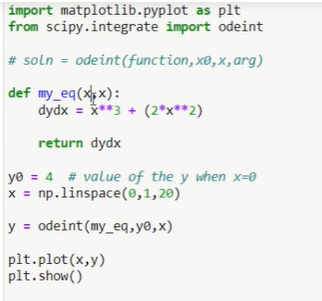

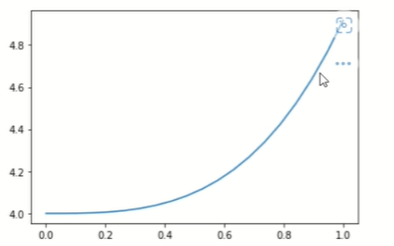

28_Analyse the simple spring mass system with python.

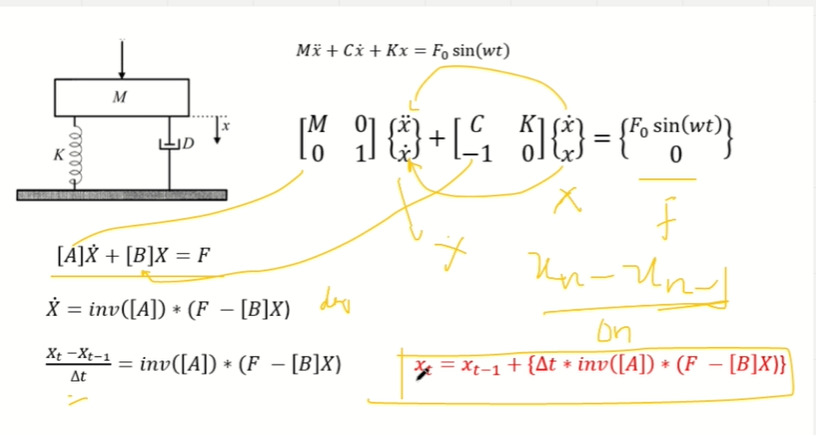

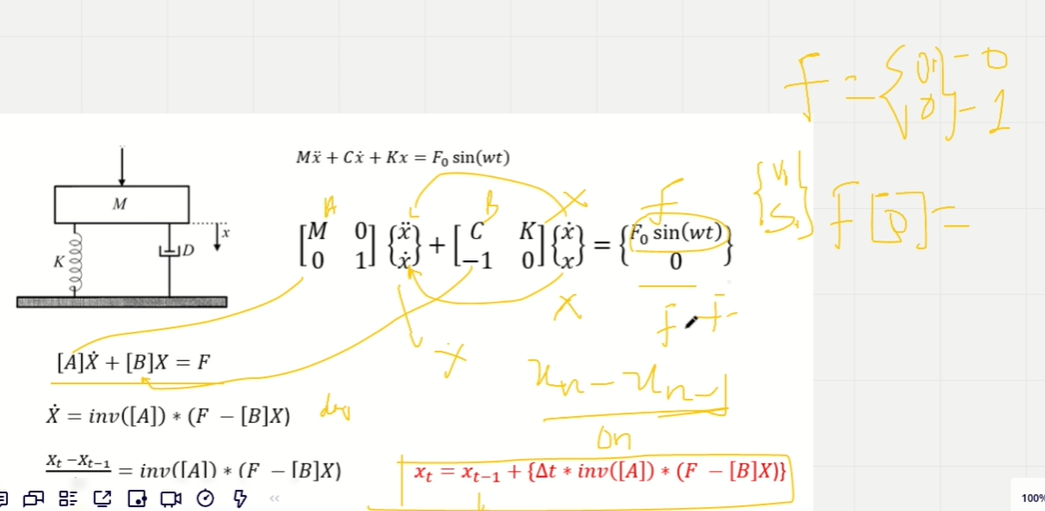

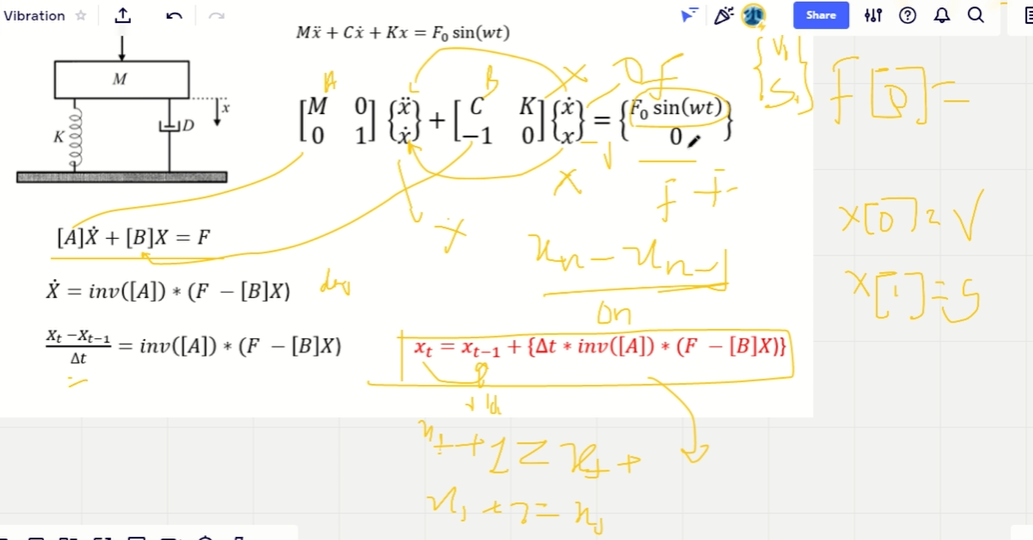

In [ ]:
# # Single degree of Freedom system P1_SDOF.py

import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import inv
# variable

M = 500  # Mass
K = 100 # stiffness
C = 100  # damping

time_step = 0.1
F0 = 100
w = 30
end_time = 60

time = np.arange(0,end_time,time_step)

x = np.array([[1],[1]])   # initial [vel,disp]

A = np.array([[M,0],
              [0,1]])

B = np.array([[C,K],
              [-1,0]])

F = np.zeros([2,1])

disp = []
vel = []
T = []

for t in time:
    F[0] = F0*np.sin(w*t)
    X = x + (time_step* inv(A).dot(F - B.dot(x)))
    x = X
    disp.append(X[1])
    vel.append(X[0])
    T.append(t)

plt.figure(figsize=(10,7.5))

plt.subplot(211)
plt.plot(T,disp,'r-',label = 'Displacement')
plt.legend()
plt.xlim(0,end_time)

plt.subplot(212)
plt.plot(T,vel,'g',label = 'Velocity')
plt.legend()


plt.xlim(0,end_time)
plt.show()

code 2

In [ ]:
# # Single degree of Freedom system  P2_SDOF.py

import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import inv
# variable

M = 500  # Mass
K = 100 # stiffness
C = 100  # damping

time_step = 0.1
F0 = 100
w = 30
end_time = 60

time = np.arange(0,end_time,time_step)

x = np.array([[1],[1]])   # initial [vel,disp]

A = np.array([[M,0],
              [0,1]])

B = np.array([[C,K],
              [-1,0]])

F = np.zeros([2,1])

disp = []
vel = []
T = []

for t in time:
    F[0] = F0*np.sin(w*t)
    X = x + (time_step* inv(A).dot(F - B.dot(x)))
    x = X
    disp.append(X[1])
    vel.append(X[0])
    T.append(t)

plt.figure(figsize=(10,7.5))

plt.subplot(211)
plt.plot(T,disp,'r-',label = 'Displacement')
plt.legend()
plt.xlim(0,end_time)

plt.subplot(212)
plt.plot(T,vel,'g',label = 'Velocity')
plt.legend()


plt.xlim(0,end_time)
plt.show()

My code

In [ ]:
# # Single degree of Freedom system My_code.py

import numpy as np
from numpy import pi, sin, cos, sqrt
import matplotlib.pyplot as plt
from numpy.linalg import inv #linear algebra modules
# variable
M = 100  # Mass
C = 10  # damping  ,Zero is no damping
K = 50 # stiffness


end_time = 100   # end time
time_step = 0.01
time = np.arange(0,end_time,time_step)
print(time)

A = np.array([[M,0],
              [0,1]])  # mass matrix 2X2
print('Mass matrix \n ',A)

B = np.array([[C,K],
              [-1,0]]) # mass matrix 2X2
print('C K matrix \n',B)

x = np.array([[2],
              [1]])   # initial [vel,disp] 2X1 matrix
print('displace \n',x)

F = np.zeros([2,1])   #2X1 zero matrix
print(F)

w = 20 # omega

# empty arrye
disp = []  # deflection
vel = []   # Velocity
T = []     # Time

F0 = 100
for t in time:
    F[0]=F0*sin(w*t) # f[0] is F0**sin(w*t)
    print('force matrix',F)  # force  matrix
    x=x + (time_step*(inv(A)).dot(F-B.dot(x)))
    # time is Scaler *, x is at time t,
    x=x # xt is assined  to xn-1
    print('Deflection',x)

    disp.append(x[1])
    vel.append(x[0])
    T.append(t)

#plt.figure(figsize=(5,5),dpi=150)
plt.figure(figsize=(5,5))
plt.plot(T,disp,label= 'Disp',lw=1)
plt.plot(T,vel,label= 'Velocity',lw=1)

plt.xticks(np.arange(0,end_time,10))
plt.yticks(np.arange(-6,8,1))

plt.legend()
plt.xlim(0,end_time)

plt.show()


 29_Single Degree freedom of System with SciPy ODEINT

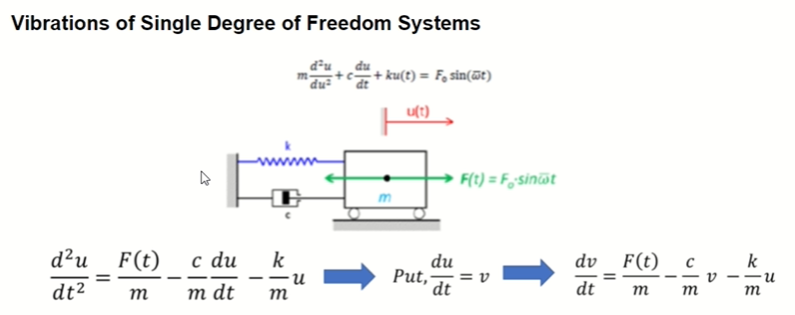

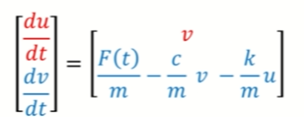

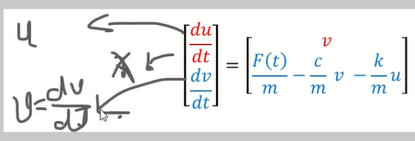

P1_SDOF Single DOF Problem

In [ ]:
# # Single DOF Problem - Scipy ODEINT

# In[20]:


import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

def SDOF(state,t):
    M = 500  # Mass
    K = 100 # stiffness
    C = 100  # damping

    F0 = 100
    w = 30

    x,xd = state

    xdd = F0*np.sin(w*t)/M - (C/M)*xd - (K/M)*x

    return [xd,xdd]

initial_cond = [1,1]
ti = 0
tf = 60
time_step = 0.01

time = np.arange(ti,tf,time_step)

state1 = odeint(SDOF,initial_cond,time)
disp = state1[:,0]
vel = state1[:,1]

plt.figure(figsize=(10,7.5))
plt.subplot(211)
plt.plot(time,disp)
plt.tight_layout(pad=3)

plt.subplot(212)
plt.plot(time,vel)

plt.show()



My _code


In [ ]:
import numpy as np
from numpy import pi, sin, cos, sqrt
import matplotlib.pyplot as plt
from scipy.integrate import odeint


def SDOF(x, t):
    M = 100  # kg Mass
    C = 10  # damping
    K = 50  # stiffness

    F0 = 100
    w = 5

    u = x[0] #zeroth  element dvdt
    v = x[1] #ones  element dudt

    dudt = v
    dvdt = (F0 * sin(w * t) / M) - (C * v / M) - (K * u / M)
    #f(t)=(F0 * sin(w * t) / m)

    return dudt, dvdt


T = np.linspace(0, 50, 1000)
x0 = [0, 3] # initial displacement 0 ,initial velocity 3
soln = odeint(SDOF, x0, T)
print(soln)

disp=soln[:,0]
velo=soln[:,1]

plt.figure(figsize=(5,5))
plt.plot(T,disp,label='displacement',color='r')
plt.plot(T,velo,label='velocity',color='g')
plt.xlim(T[0],T[-1])

plt.legend()
plt.show()


30_Plot the frequency response of the spring mass system

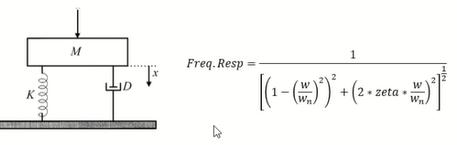



```
# 30_Frequency_Response_SDOF
```



In [ ]:
# Frequency Response For SDOF Multiple Plots

import numpy as np
import matplotlib.pyplot as plt
import math

zeta = [0.05,0.1,0.2,0.3]
r = np.linspace(0,3,300)
plt.figure(figsize=(10,7.5))
for z in zeta:
    a = (1-r**2)
    b = (2*z*r)
    f_resp = 1/np.sqrt(a**2+b**2)
    plt.plot(r,f_resp,label=r'$\zeta={}$'.format(z))
    plt.legend(loc = 'upper right',fontsize=15)

plt.xlim(r[0],r[-1])
plt.ylim(0,10)
plt.grid(linestyle='--',color = 'k')
plt.show()

30_Freq_Response_Simple.ipynb

In [ ]:
{
 "cells": [
  {
   "cell_type": "markdown",
   "id": "a0b4375e",
   "metadata": {},
   "source": [
    "# Frequency Response of Simple System"
   ]
  },
  {
   "attachments": {
    "image.png": {
     "image/png": "..."
    }
   },
   "cell_type": "markdown",
   "id": "97adef05",
   "metadata": {},
   "source": [
    "![image.png](attachment:image.png)"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": 19,
   "id": "ef1419d4",
   "metadata": {},
   "outputs": [
    {
     "data": {
      "image/png": "iVBORw0KGgoAAAANSUhEUgAAAccAAAEvCAYAAAAw6wpdAAAAOXRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjMuNCwgaHR0cHM6Ly9tYXRwbG90bGliLm9yZy8QVMy6AAAACXBIWXMAAAsTAAALEwEAmpwYAAAt/klEQVR4nO3deXwU153v/c9P+96SkJBAEkhgsAGxy4A3QhYn3jKOY8d2bhJPnEkcJ5lMlrn3zjyZyXqfSZ5JJpmMs3i5T/bkxvFMEu9rHNvYGDACs4hdiE1IoA3toK3P/UMtRxbCaqDV1cv3/XrVi+7qo+pfubC+VJ1Tp8w5h4iIiPxFgtcFiIiIRBqFo4iIyBgKRxERkTEUjiIiImMoHEVERMZQOIqIiIyR5NUXFxQUuPLycq++XkREhM2bN7c45wrHrvcsHMvLy6murvbq60VERDCzw+Ot12VVERGRMRSOIiIiY0wYjmaWZmavmdk2M9tpZl8fp42Z2T1mVmtm281s2eSUKyIiMvmC6XPsA97hnOs2s2TgFTN7yjm3YVSba4E5gWUlcG/gTxERkagz4ZmjG9YdeJscWMbOVn4j8MtA2w1ArplNC22pIiIi4RFUn6OZJZrZVqAJeM45t3FMkxLg6Kj39YF1IiIiUSeocHTODTnnlgClwAozqxzTxMb7sbErzOwuM6s2s+rm5uZzLlZERCQczmm0qnOuHXgRuGbMR/VA2aj3pUDDOD//gHOuyjlXVVh4xj2XIiIiESGY0aqFZpYbeJ0OvAvYM6bZo8AdgVGrq4AO51xjqIsVEREJh2BGq04DfmFmiQyH6UPOucfN7G4A59x9wJPAdUAt0AvcOUn1Shw50trLjmMdXDItm9mFWV6XIyJxZMJwdM5tB5aOs/6+Ua8d8JnQlibxyjnHj188wHee2QtAgsFfX17OV26Yj9l43dsiIqHl2dyqImdz/9o6vvPMXv5q8XQ+dmUFv9t0hJ+tO0RxThqffNtsr8sTkTigcJSIsu9EF997dh/XLCjm+7ctISHBWFzqo/PUIP/69B5Wzy1k3rQcr8sUkRinuVUlonzlkRoyUxP5f2+qJCFh+BKqmfHNmxaSmZrE957b53GFIhIPFI4SMTYdamNDXRuffcccCrJS3/SZLyOZu66axXO7TrC9vt2bAkUkbigcJWL88M+1TMlM4YMrZoz7+Z1XVpCZksgv14/7+DURkZBROEpEONDczUv7mvno5eWkpySO2yYrNYn3Lp7OE9sb6To9EOYKRSSeKBwlIjxUfZTEBOO2FWVv2e7WS8s4NTDEE9s1x4SITB6Fo3huYMjP7zcf4+0XT2Vqdtpbtl1alsvswkz++PqxMFUnIvFI4SieW7uvmZbuPm6tKp2wrZlx3cJpbDrUxsme/jBUJyLxSOEonntieyM5aUmsuXhqUO3fPb8Yv4Pn9zRNcmUiEq8UjuKpvsEhntt1gncvKCYlKbi/jpUlOUzzpfHszuOTXJ2IxCuFo3jqlf0tdPUNcv3CaUH/jJlx9fwi1u5vpm9waBKrE5F4pXAUTz2z8zjZaUlccVHBOf3c6jmFnB7ws/nwyUmqTETimcJRPOOc48W9zayeWxj0JdURK2flk5hgrKttmaTqRCSeKRzFM7saO2nq6uPtQQ7EGS07LZmlZbm8sl/hKCKhp3AUz7y4txmAt80tPK+fv3JOAduPddDRq9lyRCS0FI7imRf2NLGwxEdhdurEjcdx+ewCnIPXDrWFuDIRiXcKR/FEe28/W46c5O0Xn99ZI8CiUh/JiUb1YYWjiISWwlE88fL+FvwO1lxy7v2NI9KSE6ks8bFFI1ZFJMQUjuKJF/Y2kZeRzOLS3AvaTtXMPLbVd+h+RxEJKYWjhJ3f73gpcAtHYoJd0LaWz8ynf9BPzbHOEFUnIqJwFA/sauyktaf/vEepjrZ8Zh6ALq2KSEgpHCXsNtS1AsOjTS9UYXYqM6dkaFCOiISUwlHCbv2BVioKMin2vfWzG4O1fGYemw+fxDkXku2JiCgcJawGh/y8drCNVbPyQ7bNqpn5tHT3c7i1N2TbFJH4pnCUsNrZ0ElX3yCrZk0J2TZH+h01CbmIhIrCUcJqpL/xshCG45ypWeSkJVGtcBSREFE4Slitr2tldmEmU3NC098IkJBgLJ2Rx+tHFI4iEhoKRwmbgSE/mw62cdns0J01jlhc6mN/Uzen+jUZgIhcOIWjhM2OYx309A9x2awLv4VjrIWluQz5HbsaNRmAiFw4haOEzfoDw/2NK0M4UnXEolIfADvq20O+bRGJPwpHCZsNda3MLcqiIOv8HlH1Vopy0piancr2+o6Qb1tE4o/CUcKif9BP9aGTIR2lOtaiUh/bjykcReTCKRwlLLbXt3NqYGhSBuOMWFiSy4Hmbrr7BiftO0QkPigcJSzWH2jFDFZWTO6Zo3OwU2ePInKBJgxHMyszsxfMbLeZ7TSzz43TZo2ZdZjZ1sDylckpV6LV+rpWLinOIS8zZdK+Y+HIoByFo4hcoKQg2gwCf++c22Jm2cBmM3vOObdrTLuXnXM3hL5EiXZ9g0NsPnySD62cOanfU5CVSkluugbliMgFm/DM0TnX6JzbEnjdBewGSia7MIkdrx9pp2/QP6n9jSMWlvh05igiF+yc+hzNrBxYCmwc5+PLzGybmT1lZgtCUZzEhpH+xhUVob+/cayFpT4OtvTQcWpg0r9LRGJX0OFoZlnA74HPO+fGTkOyBZjpnFsM/AB4+CzbuMvMqs2surm5+TxLlmizvq6VBdNz8KUnT/p3jUwGUKOzRxG5AEGFo5klMxyMv3HO/WHs5865Tudcd+D1k0CymZ0xR5hz7gHnXJVzrqqwsPACS5docHpgiK1H2if1/sbRKqcrHEXkwgUzWtWAnwC7nXPfO0ub4kA7zGxFYLutoSxUotOWwyfpHwpPfyNAXmYKJbnp6ncUkQsSzGjVK4CPADvMbGtg3ZeAGQDOufuAW4BPmdkgcAq43TnnQl+uRJv1da0kJhiXlk9+f+OIhSU+djZoAnIROX8ThqNz7hXAJmjzQ+CHoSpKYsf6A61UlvjITpv8/sYRlSU5PL3zOF2nB8L6vSISOzRDjkya3v5BttWHr79xxIKS4X7HXTp7FJHzpHCUSVN96CQDQy5s/Y0jRgblqN9RRM6XwlEmzfq6VpISjKqZeWH93sLsVIpz0tTvKCLnTeEok2ZDXSuLSn1kpgYz7iu0KktydDuHiJw3haNMiu6+QbbXd4T9kuqIBdN9HGjuprdfj68SkXOncJRJselQG0N+x2WzzpgLIiwqS3z4Hexu1KVVETl3CkeZFBsOtJKcaCwPc3/jiIUlIzPlKBxF5NwpHGVSvHqglaVleaSnJHry/UU5qRRkpWjEqoicF4WjhFx7bz81DR1cfpE3/Y0AZsaC6T4NyhGR86JwlJBbf6AV5+DKi7zpbxxRWZLD/qZuTg8MeVqHiEQfhaOE3LoDLWSmJLK4LNfTOhaW+BjyO/Ye7/K0DhGJPgpHCbl1ta2snDWF5ERv/3ot0Ew5InKeFI4SUsfaT3GwpYcrPL6kClCal44vPZmdDQpHETk3CkcJqXW1LYD3/Y0wPChnYYlPt3OIyDlTOEpIrattoSArlblFWV6XAsCCkhz2Hu+if9DvdSkiEkUUjhIyzjnW1bZyxUVTMHvLR4CGTeV0H/1Dfvad0KAcEQmewlFCZt+Jblq6+yKiv3FEZWCmHPU7isi5UDhKyLwS6G+MpHCcmZ9BdmqS+h1F5JwoHCVkXq1toaIgk5LcdK9LeUNCgjF/eo5u5xCRc6JwlJAYGPKzoW64vzHSVJb42N3YyeCQBuWISHAUjhIS2+vb6ekf4orZkXNJdURlSQ59g34ONPd4XYqIRAmFo4TEK/tbMcOzhxu/lZHHV+nSqogES+EoIfHiviYWleaSm5HidSlnqCjIIj05UU/oEJGgKRzlgp3s6Wfr0XbWzC30upRxJQYG5eh2DhEJlsJRLtja/c04B2sujsxwBKicnsPOhk6G/M7rUkQkCigc5YK9tLeZvIxkFpXmel3KWVWW+OjtH+JgiwbliMjEFI5yQfx+x0v7mrlqTiGJCZExZdx4NFOOiJwLhaNckJqGDlp7+iP6kirARVOzSElK0KAcEQmKwlEuyIt7mwFYHaGDcUYkJyYwrzhbt3OISFAUjnJBXtzbxKJSHwVZqV6XMqHKEh87j3Xi16AcEZmAwlHOW6TfwjFWZYmPrr5Bjp7s9boUEYlwCkc5by/sbcLv4B3zirwuJSiV0zVTjogER+Eo5+25XSeYmp3KosBI0Eg3tziL5ETT46tEZEIKRzkvpweGeGlfM++cV0RCBN/CMVpqUiJzi7J1O4eITGjCcDSzMjN7wcx2m9lOM/vcOG3MzO4xs1oz225myyanXIkU6+ta6e0f4t3zo+OS6ojK6T52HOvAOQ3KEZGzC+bMcRD4e+fcPGAV8Bkzmz+mzbXAnMByF3BvSKuUiPOnXSfISEmMyKdwvJVFZT7aewc40qZBOSJydhOGo3Ou0Tm3JfC6C9gNlIxpdiPwSzdsA5BrZtNCXq1EBL/f8afdJ1g9p5C05ESvyzknS8pyAdh6tN3TOkQksp1Tn6OZlQNLgY1jPioBjo56X8+ZASoxoqahgxOdfVwdZZdUAeYWZZOWnMC2o+p3FJGzCzoczSwL+D3weefc2OF+443IOKNTx8zuMrNqM6tubm4+t0olYjy36wQJBm+/ZKrXpZyz5MQEKqf72Hr0pNeliEgECyoczSyZ4WD8jXPuD+M0qQfKRr0vBRrGNnLOPeCcq3LOVRUWRseN43Kmp2qOc2l5PvmZkfdg42AsKculpqGTgSG/16WISIQKZrSqAT8BdjvnvneWZo8CdwRGra4COpxzjSGsUyLEvhNd1DZ1c8Oi6O1SXlyWS/+gnz2NXV6XIiIRKimINlcAHwF2mNnWwLovATMAnHP3AU8C1wG1QC9wZ8grlYjw+PZGzOA9lcVel3Le3hiUU9/OwtLomMBARMJrwnB0zr3C+H2Ko9s44DOhKkoi15M7GllRns/U7DSvSzlvpXnpTMlMYdvRdj6yaqbX5YhIBNIMORK0kUuq10fxJVUAM2NxWa5u5xCRs1I4StCeCFxSvSaKL6mOWFKWy4HmbjpPD3hdiohEIIWjBC0WLqmOWFyWi3NQU6/7HUXkTApHCcre413sj4FLqiOWlOYC8LourYrIOBSOEpSHtx4jMcG4bmFshKMvI5nZhZlsOazJAETkTApHmZDf73jk9WOsnlNAQVaq1+WEzPKZeWw+chK/X0/oEJE3UzjKhDYcbKWh4zQ3LSv1upSQqpqZT3vvAHUtPV6XIiIRRuEoE3r49WNkpSZx9bzom2j8rSybmQfA5sNtHlciIpFG4Shv6fTAEE/tOM41lcWkp0TX46kmMrswk9yMZDar31FExlA4ylt6btcJuvoGef/S2HsCmZmxfEYe1QpHERlD4Shv6Q9b6inOSWPlrClelzIplpfnUdfcQ1tPv9eliEgEUTjKWTV2nOKlfc3cvLyExIS3nF43ai2fMdzv+PoRnT2KyF8oHOWsHtpUj9/B7ZfO8LqUSbO4LJekBNOlVRF5E4WjjGvI73io+ihXzSmgLD/D63ImTVpyIgtKfBqUIyJvonCUca3d38yx9lMxfdY4ompmHtuOttM/6Pe6FBGJEApHGdeDrx1hSmYKV8+PrXsbx3NpeT59g36217d7XYqIRAiFo5yhqes0z+9u4ublpaQkxf5fkRUV+QBsPKjJAERkWOz/5pNz9tuNRxn0O26/tMzrUsIiPzOFS4qz2VDX6nUpIhIhFI7yJv2Dfn698TBrLi5kVmGW1+WEzcqKfKoPnWRgSP2OIqJwlDGe2NFAc1cfd15R4XUpYbVq1hRODQyxXQ8/FhEUjjKKc46frTvErMJMrrqowOtywuov/Y66tCoiCkcZZcuRdrbXd3Dn5eUkxOiMOGczJSuVOVOz2FinQTkionCUUX627iDZaUm8P8ae2xisVbOmUH2ojUH1O4rEPYWjAHCktZcndzTywRUzyExN8rocT6yclU9P/xA1DZ1elyIiHlM4CgD3rz1AUkICf3NlfA3EGW2k31G3dIiIwlFo6jrNf26u5+blJRTlpHldjmemZqdx0dQs1tW2eF2KiHhM4Sj85JWDDA75+eTq2V6X4rkrLyrgtYNtnB4Y8roUEfGQwjHOdZwa4DcbjnDdwmmUF2R6XY7nVs8toG/Qr6d0iMQ5hWOc+9m6g3T3DfKpNTprBFhZMYXkROPl/bq0KhLPFI5x7GRPPz95+SDvWVDEguk+r8uJCJmpSSydkccrtc1elyIiHlI4xrEHXq6ju3+QL1w91+tSIspVFxVQc6yT1u4+r0sREY8oHONUc1cfP193iPcums4lxTlelxNRrppbCMC6A7qlQyReKRzj1L0vHqB/yM/n3zXH61IizsISH770ZF7Zr0urIvFK4RiHjrT28usNh7l5WUlcPZYqWIkJxuWzp/DK/hacc16XIyIeUDjGoX99eg+JCcYXr77Y61Ii1lVzCmnoOM2B5m6vSxERD0wYjmb2UzNrMrOas3y+xsw6zGxrYPlK6MuUUKk+1MYTOxr55NtmUeyL39lwJrLm4uF+xz/vafK4EhHxQjBnjj8HrpmgzcvOuSWB5RsXXpZMBr/f8b8e30VRTip3rZ7ldTkRbXpuOvOm5fD8boWjSDyaMBydc2sBPeQuBjy89Rjb6jv4n++5hIyU+Hzyxrl4xyWFVB8+SUfvgNeliEiYharP8TIz22ZmT5nZghBtU0Koo3eAbz65m8Vludy0tMTrcqLCOy4pYsjvWKtRqyJxJxThuAWY6ZxbDPwAePhsDc3sLjOrNrPq5mb9wgmn7zy7h7aefv7lfZUkJJjX5USFJWW55GemqN9RJA5dcDg65zqdc92B108CyWZWcJa2DzjnqpxzVYWFhRf61RKkrUfb+c3GI3z08goqSzRNXLASE4w1cwt5YW8TQ37d0iESTy44HM2s2Mws8HpFYJuaWiRCDA75+ac/7mBqdipffLemiTtX75g3lfbeAV4/oqd0iMSTCUdlmNlvgTVAgZnVA18FkgGcc/cBtwCfMrNB4BRwu9Od0xHjvpcOsLOhk/s+vIysVA3COVdXzSkkKcF4fk8TVeX5XpcjImEy4W9L59wHJ/j8h8APQ1aRhMzuxk7+4/n9vHfxdK6pnOZ1OVHJl57Miop8nt15nH+45hKvyxGRMNEMOTFqYMjP3z+0DV96Ct/4Kw0gvhDXVhZzoLmH/Se6vC5FRMJE4Rij7nl+P7saO/nmTZXkZaZ4XU5Ue8+CYszgqZrjXpciImGicIxBrx5o4Ycv1HLL8lLevaDY63Ki3tScNJbPyOPJHY1elyIiYaJwjDFtPf184XdbqSjI5Ou6nBoy11QWs+d4F4daerwuRUTCQOEYQ/x+x//4z22c7BngBx9cSqZGp4bMNZXDZ+C6tCoSHxSOMeTHL9by/J4mvnTdJSyYrpv9Q6k0L4PFpT6ertGlVZF4oHCMES/saeK7z+3jfUum89eXl3tdTky6pnIa2+o7qD/Z63UpIjLJFI4x4FBLD3/34OvMK87hW+9fRGDCIgmx6xcO3yv62DadPYrEOoVjlGvv7edjv9hEUoJx/0eWk56S6HVJMWvGlAyWzcjlka3HvC5FRCaZwjGK9Q0OcdevNlPfdor7P1JFWX6G1yXFvPctLWHP8S72HO/0uhQRmUQKxyjlnOMf/ms7rx1s4zsfWMSKCs37GQ7XL5xGYoLx8OsNXpciIpNI4RiFnHN84/FdPLy1gf/xnou5cYkeXhwuU7JSWT2ngEe3HsOvx1iJxCyFYxT69z/t52frDvGxKyr49JrZXpcTd963tISGjtO8dqjN61JEZJIoHKPM/S8d4J7n93NrVSlfvmGeRqZ64Or5RWSkJGpgjkgMUzhGkR+9UMu3ntrDDYum6ZYND2WkJHHNgmIe39ZIb/+g1+WIyCRQOEYB5xzf/9M+vvPMXt63ZDrfv20JiQkKRi/ddmkZXX2DPLlD08mJxCKFY4Qb8ju+/tguvv+n/dyyvJTv3rqEpEQdNq+tqMhnVkEmv9t0xOtSRGQS6LdsBDs9MMSnf7OZn796iL+5soJv37xIZ4wRwsy47dIyNh06SW1Tt9fliEiIKRwjVFtPPx/83xt4dtcJvvre+Xz5hvkkKBgjyvuXlZKUYPxn9VGvSxGREFM4RqB9J7p4/4/Xsauhk3s/tIw7r6jwuiQZR2F2Ku+aV8Tvt9TTP+j3uhwRCSGFY4R5ZOsxbvzhOnr6h/g/n1jFNZXTvC5J3sJtK8po6e7nuV0nvC5FREJI4Rgh+gf9fPWRGj734FYWlvh44rNXsnxmntdlyQRWzymkLD+dX7x6yOtSRCSEFI4RoK65mw/cv55frD/MJ66q4DefWMnUnDSvy5IgJCYYd6wq57VDbexs6PC6HBEJEYWjh/x+x8/XHeS6e17mUEsP935oGf90/XySdatGVLm1qoz05ESdPYrEEP0W9kj9yV4+/JONfO2xXayaNYVnv7CaaxeqfzEa+TKSuWlZCY9sbaCtp9/rckQkBBSOYdY/6OfHL9Zy9ffWsu1oO996/0J+9tFLKdJl1Kj215eV0zfo50FNCiASE5K8LiCevLK/ha88WkNdcw/vnl/El2+YrwcUx4iLi7O5fPYUfvnqYT5+5SxSkvTvTpFopv+Dw2Dv8S4+/otqPvyTjQz5HT/76KU8cEeVgjHGfGL1LI53ntbTOkRigM4cJ9GR1l7+/U/7eHjrMbJSkvjv757Lx6+aRVpyotelySRYM7eQS4qzuX9tHTcvK9WMRiJRTOE4Cfaf6OKBtXX88fVjJCYYd62exd2rZ5OXmeJ1aTKJzIxPrZnN5x7cyp92n+DdC4q9LklEzpPCMUScc2w6dJL7XzrA83uaSEtO4EMrZ/CpNRdR7NNgm3hx/cJp/Nuze7n3pQNcPb9Iz9wUiVIKxwvU0TvAH1+v57evHWXviS7yMpL5/LvmcMdl5eTrTDHuJCUmcNdVs/jyIzvZUNfGZbOneF2SiJwHheN5GBjy80ptC49ubeDJHY30DfpZVOrjW+9fyPuWlJCeoj7FePaBqjLu+XMt//H8Pi6bfZnX5YjIeVA4BqlvcIiNdW08VdPIUzXHae8dICctiVuWl/LBFTOoLPF5XaJEiLTkRD6zZjZfe2wXr9a2cPlFBV6XJCLnSOF4Fs45jrT18kptCy/saWJdbSunBobITEnk6vlF3LBoOlfNLSA1SWeJcqbbV8zg/rV1fO+5fVw2e4r6HkWizIThaGY/BW4AmpxzleN8bsB/ANcBvcBHnXNbQl3oZDs9MMSe411sr29n48E2Nh1so6mrD4DSvHQ+UFXK2y+eymWzp+hWDJlQWnIin3n7RfzzwzWs3d/C2+YWel2SiJyDYM4cfw78EPjlWT6/FpgTWFYC9wb+jEidpwc43NLLodYeDrf2UNfcw86GTmqbuxnyOwCKc9JYNWsKKyryWTVrCrMLM/Uvfzlnt1aVce+LB/jes3tZPadAf4dEosiE4eicW2tm5W/R5Ebgl845B2wws1wzm+acawxVkW9lz/FO9p3opn/QT/+gn77BIfoH/ZwaGKKtp5/Wnn7auvtp7emjuauPk70Db/r54pw05k3L5ur5RSyYnkNliY/SvHT9IpMLlpKUwOfeNYf/+V/beWJHIzcsmu51SSISpFD0OZYAR0e9rw+sOyMczewu4C6AGTNmhOCr4ZGtDdz74oFxP/OlJzMlM4UpWSlUFGRyaXk+M6dkMHNKJuVTMpmRn6GRpTKpbl5Wyk9fOci/Pr2Hq+cXqY9aJEqEIhzHO8Vy4zV0zj0APABQVVU1bptzdecV5dy8rISUxERSkhLeWNKSEkjScxHFY4kJxj9fP58P/2Qjv3z1MJ9YPcvrkkQkCKEIx3qgbNT7UqAhBNsNytTsNKZmawYaiVxXzilgzcWF/ODP+7lleammERSJAqE4tXoUuMOGrQI6wtXfKBIt/p9r59HdN8i//2mf16WISBAmDEcz+y2wHrjYzOrN7G/M7G4zuzvQ5EmgDqgF/jfw6UmrViRKXVyczUdWzeTXGw5Tc6zD63JEZAI2PMg0/Kqqqlx1dbUn3y3ihY5TA7zzuy9RmpfOHz51uR5pJRIBzGyzc65q7HqNWBEJE196Ml+67hK2Hm3noeqjE/+AiHhG4SgSRjctLWFFeT7/39N7aOnu87ocETkLhaNIGJkZ/3JTJb19Q3zt0Z1elyMiZ6FwFAmzOUXZfPYdF/H49kaerjnudTkiMg6Fo4gH7l4zm/nTcvjyIzV0jJnSUES8p3AU8UByYgLfvmURbT39fPXRGq/LEZExFI4iHqks8fF375jDw1sbeGTrMa/LEZFRFI4iHvrM22ezfGYe//xwDfUne70uR0QCFI4iHkpKTODfb12Cc/DF321745miIuIthaOIx2ZMyeAbNy7gtUNtfF9zr4pEBIWjSAR4/7JSbqsq4wd/ruWFvU1elyMS9xSOIhHi6zcuYN60HL7wu63qfxTxmMJRJEKkJSdy74eWMTTk+OSvNtPbP+h1SSJxS+EoEkHKCzK554NL2d3YyRd/tw2/BuiIeELhKBJh3n7JVP7p+vk8vfM4//bsXq/LEYlLSV4XICJn+tgV5dQ2dfPjFw8wuzCLm5eXel2SSFzRmaNIBDIzvnHjAi6fPYV//MN2Nta1el2SSFxROIpEqOTEBO790HJm5Gfw8V9UU3Osw+uSROKGwlEkgvkykvn1x1eSk57MHT99jdqmbq9LEokLCkeRCDfNl86vP76SBDM+8pONugdSJAwUjiJRoKIgk1/9zQp6+gb58P+/kabO016XJBLTFI4iUWLetBx+/rEVNHf1cev96znWfsrrkkRilsJRJIosm5HHrz6+ktaefm69bz1HWnWJVWQyKBxFosyyGXn89hOr6O0f5AP3v6pBOiKTQOEoEoUqS3w8eNdlDPnhtvvXs+1ou9clicQUhaNIlLq4OJuHPrmK9JREbn9gA8/tOuF1SSIxQ+EoEsVmFWbxx09fwdyiLO76VTU/X3fQ65JEYoLCUSTKFWan8tu7VvHOS4r42mO7+PpjOxkc8ntdlkhUUziKxICMlCTu/8hyPnp5OT9bd4g7fvoard19XpclErUUjiIxIjHB+NpfLeDbtyyi+vBJ3vuDV9he3+51WSJRSeEoEmNurSrj93dfjplxy33refC1IzinhyaLnAuFo0gMWljq47HPXsmK8nz+8Q87+Nvfvk5H74DXZYlEDYWjSIzKz0zhFx9bwT9ccwnP1BznunteZtOhNq/LEokKCkeRGJaYYHxqzWx+/6nLSUo0brt/Pd95Zg99g0NelyYS0YIKRzO7xsz2mlmtmf3jOJ+vMbMOM9saWL4S+lJF5HwtLsvlib+7iluWl/KjFw5wwz2v8PqRk16XJRKxJgxHM0sEfgRcC8wHPmhm88dp+rJzbklg+UaI6xSRC5SVmsS3b1nMz++8lJ6+QW6+91W++eRuTvXrLFJkrGDOHFcAtc65OudcP/AgcOPkliUik2XNxVN55guruX3FDB5YW8e7vvcST9c0akSryCjBhGMJcHTU+/rAurEuM7NtZvaUmS0ISXUiMimy05L55k0LeeiTl5GdlsTdv97CHT99jQPNesKHCAQXjjbOurH/xNwCzHTOLQZ+ADw87obM7jKzajOrbm5uPqdCRST0VlTk8/hnr+Sr753P1iPtXPP9tXzrqd109w16XZqIp4IJx3qgbNT7UqBhdAPnXKdzrjvw+kkg2cwKxm7IOfeAc67KOVdVWFh4AWWLSKgkJSZw5xUV/Pm/r+HGJSXc/1Idb/v2C/xs3UGNapW4FUw4bgLmmFmFmaUAtwOPjm5gZsVmZoHXKwLbbQ11sSIyeQqzU/m3Dyzm4c9cwdyibL7+2C7e+d2X+MOWeob86o+U+DJhODrnBoG/BZ4BdgMPOed2mtndZnZ3oNktQI2ZbQPuAW536t0XiUpLynL5P59YyS8/tgJfejJffGgb19/zMk/XHMevkJQ4YV5lWFVVlauurvbku0UkOH6/44kdjXz32b0cau1lblEWn15zETcsmkZSouYQkehnZpudc1VnrFc4ishEBof8PLGjkR+9UMu+E93MyM/g7rfN5ublJaQmJXpdnsh5UziKyAXz+x1/2n2CH71Qy7b6DgqyUvnwqhn8t5UzmJqd5nV5IudM4SgiIeOcY11tKz9dd5A/72kiJTGBGxZN484rKlhY6vO6PJGgnS0ck7woRkSim5lx5ZwCrpxTQF1zN7949RD/tbmeP7x+jGUzcrnt0jJuWDSdzFT9ipHopDNHEQmJztMD/Gd1Pb997Qi1Td1kpiRyw6Lp3LaijKVluQTu9hKJKLqsKiJh4Zxjy5GT/G7TUR7b1sipgSHmTM3itkvLeO/i6RTlqG9SIofCUUTCrrtvkMe3NfDgpqNsPdqOGaysyOevFpdwbWUxeZkpXpcocU7hKCKeqm3q5rFtDTy2rYG6lh6SEoyr5hTw3sXTeee8InzpyV6XKHFI4SgiEcE5x86GTh7b3sDj2xo51n6KpATjstlTuHp+Ee+aV8T03HSvy5Q4oXAUkYjj9zteP9rOs7uO89yuE9Q19wCwsMTH1fOLeOe8qcyflqPBPDJpFI4iEvFqm7p5btcJntt1nNePtuMcFGSlsnpOAVfNLeDKiwopzE71ukyJIQpHEYkqTV2nWbuvhZf3N/Py/hbaevoBmD8th9VzC1k9p4BlM/NIS9b0dXL+FI4iErX8fseuxk5e2tfM2n3NbD58kkG/IyUpgSVluaysyGdFRT7LZ+aRkaKJByR4CkcRiRndfYNsrGtl48E2Nta1UtPQyZDfkZRgVJb43gjLpTPyyNftIvIWFI4iErO6+wbZcvgkGw+28trBNrYd7aB/yA/AjPwMlpTlDi8zclkwPUdPEpE3aG5VEYlZWalJw/2QcwsBOD0wxLaj7WwNLJsOtfHotgYAkhON+dN9LC3LZXGZjwXTfcwqyNTzKeVNdOYoInHheMdpth49yetH29l6pJ0dxzro7R8CIDUpgUuKs5k/PYf5033Mn5bDvGnZ6r+MA7qsKiIyyuCQnwPNPexq7GBXQyc7A0vHqQEAzKCiIJN503KYOzWbOUVZzC3KYuaUTJJ1lhkzdFlVRGSUpMQELi7O5uLibG5aOrzOOUdDx+lAWA6H5o76Dp7c0cjIeURyolFRkMmcQGDOmZrN3KIsygsUmrFE4SgiEmBmlOSmU5KbztXzi95Yf6p/iAPN3exv6mLfiW72n+impqGDJ2v+EppJCUZpXjrlBZmUT8mkoiCT8oJMKqZkUpKXTmKCZvmJJgpHEZEJpKckUlnio7LE96b1pweGqG3qfmM52NrDoZYeNh1soyfQnwnDZ5tl+RlUTBkOzPKCTGbkZ1CaNxzEmsgg8igcRUTOU1ry+KHpnKO5u49DLb0caul5IzQPtvTw6oFWTg0Mval9QVYqpXnpgSWDksDrsrx0SnIzSE9ReIabwlFEJMTMjKnZaUzNTmNFRf6bPnPOcaKzj/qTvdSfPDXqz1PUHOvgmZ3HGRh680DJgqwUSnLTKfalUZyTRpEvjWm+NIpyht8X+9I0sjbE9F9TRCSMzGw45HxpVJWf+bnf72jq6uNY+19CcyRA65qHzzy7Tg+e8XM5aUmB7aZTnJMaCM10in2pFGalUZCdwpTMVFKSNGgoGApHEZEIkpDwl/BcPnP8Nj19gxzvPM2JjtM0dpweft15muOB13saO2nu7mO8O/V86ckUZqdSkJVCQVYqBVmpFGanUpiVSkF2ioI0QOEoIhJlMlOTmF2YxezCrLO2GRzy09zdR2PHaVq6+mjp7qelu4/mrj5auoeXmmMdtHT309135pkoDAfplMwU8jJTyMtIIT8z+S+vM4bX52cmk5cxvM6XnkxCjIzKVTiKiMSgpMQEpvnSmeZLn7Dt6YEhmrv6aO7ueyNIR0K0rbefkz391J/spebYAG09/W/MWztWgkFuRgp5GYHAzBx+7UsfXnJG/kwb9To9CV96csTNd6twFBGJc2nJiZTlZ1CWnzFhW+ccvf1DtPX009478EZ4Dr/vD7wfDtGjbb1sr++n89TgGSN0z6whgZy0N4focJAmvbEuJ/B+wXRfULVeCIWjiIgEzczITE0iMzWJsvyJ24/oGxyi89QgnacH6Dg1QOepv/zZeXrwTes6Tg3Q1HWa/U1db/zM6P7Tr713Ph+9oiL0OzeKwlFERCZdalIihdmJFGannvPP+v2Orr5BOk8N0HV68Ly2ca4UjiIiEtESEuyNy6xh+86wfZOIiEiUUDiKiIiMoXAUEREZQ+EoIiIyRlDhaGbXmNleM6s1s38c53Mzs3sCn283s2WhL1VERCQ8JgxHM0sEfgRcC8wHPmhm88c0uxaYE1juAu4NcZ0iIiJhE8yZ4wqg1jlX55zrBx4EbhzT5kbgl27YBiDXzKaFuFYREZGwCCYcS4Cjo97XB9adaxsREZGoEEw4jjfF+tgHoQTTBjO7y8yqzay6ubk5mPpERETCLphwrAfKRr0vBRrOow3OuQecc1XOuarCwsJzrVVERCQszI33NMzRDcySgH3AO4FjwCbgvznndo5qcz3wt8B1wErgHufcigm22wwcvqDq/6IAaAnRtqJRPO+/9j1+xfP+x/O+Q2j3f6Zz7oyztQnnVnXODZrZ3wLPAInAT51zO83s7sDn9wFPMhyMtUAvcGcQ2w3ZqaOZVTvnqkK1vWgTz/uvfY/PfYf43v943ncIz/4HNfG4c+5JhgNw9Lr7Rr12wGdCW5qIiIg3NEOOiIjIGLESjg94XYDH4nn/te/xK573P573HcKw/xMOyBEREYk3sXLmKCIiEjJRFY7xPAF6EPu+xsw6zGxrYPmKF3VOBjP7qZk1mVnNWT6P2eMOQe1/LB/7MjN7wcx2m9lOM/vcOG1i8vgHue8xeezNLM3MXjOzbYF9//o4bSb3uDvnomJh+DaSA8AsIAXYBswf0+Y64CmGZ+xZBWz0uu4w7vsa4HGva52k/V8NLANqzvJ5TB73c9j/WD7204BlgdfZDN9zHS//3wez7zF57APHMivwOhnYCKwK53GPpjPHeJ4APZh9j1nOubVA21s0idXjDgS1/zHLOdfonNsSeN0F7ObMeZtj8vgHue8xKXAsuwNvkwPL2AEyk3rcoykc43kC9GD367LAZYinzGxBeEqLCLF63M9FzB97MysHljJ8FjFazB//t9h3iNFjb2aJZrYVaAKec86F9bgHNQlAhAjZBOhRKJj92sLwNEjdZnYd8DDDz9eMB7F63IMV88fezLKA3wOfd851jv14nB+JmeM/wb7H7LF3zg0BS8wsF/ijmVU650b3u0/qcY+mM8eQTYAehSbcL+dc58hlCDc8o1GymRWEr0RPxepxD0qsH3szS2Y4HH7jnPvDOE1i9vhPtO+xfuwBnHPtwIvANWM+mtTjHk3huAmYY2YVZpYC3A48OqbNo8AdgVFMq4AO51xjuAudBBPuu5kVm5kFXq9g+Ni2hr1Sb8TqcQ9KLB/7wH79BNjtnPveWZrF5PEPZt9j9dibWWHgjBEzSwfeBewZ02xSj3vUXFZ1kzQBejQIct9vAT5lZoPAKeB2FxjSFe3M7LcMj8orMLN64KsMd9DH9HEfEcT+x+yxB64APgLsCPQ/AXwJmAExf/yD2fdYPfbTgF+YWSLDgf+Qc+7xcP6+1ww5IiIiY0TTZVUREZGwUDiKiIiMoXAUEREZQ+EoIiIyhsJRRERkDIWjiIjIGApHERGRMRSOIiIiY/xfCq7TIfzyHcgAAAAASUVORK5CYII=\n",
      "text/plain": [
       "<Figure size 540x360 with 1 Axes>"
      ]
     },
     "metadata": {
      "needs_background": "light"
     },
     "output_type": "display_data"
    }
   ],
   "source": [
    "import numpy as np\n",
    "import matplotlib.pyplot as plt\n",
    "\n",
    "zeta = 0.3\n",
    "r = np.linspace(0,3,300)\n",
    "\n",
    "a = 1-r**2\n",
    "b = (2*zeta*r)**2\n",
    "fr = 1/np.sqrt(a**2+b**2)\n",
    "\n",
    "plt.figure(figsize=(7.5,5))\n",
    "plt.plot(r,fr)\n",
    "plt.show()\n"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": 18,
   "id": "e3df2f18",
   "metadata": {},
   "outputs": [
    {
     "data": {
      "image/png": "...\n",
      "text/plain": [
       "<Figure size 540x360 with 1 Axes>"
      ]
     },
     "metadata": {
      "needs_background": "light"
     },
     "output_type": "display_data"
    }
   ],
   "source": [
    "import numpy as np\n",
    "import matplotlib.pyplot as plt\n",
    "\n",
    "zeta = [0.2,0.3,0.4,0.5]\n",
    "r = np.linspace(0,3,300)\n",
    "\n",
    "plt.figure(figsize=(7.5,5))\n",
    "for z in zeta:\n",
    "    a = 1-r**2\n",
    "    b = (2*z*r)**2\n",
    "    fr = 1/np.sqrt(a**2+b**2)\n",
    "    plt.plot(r,fr,label=r'$\\zeta={}$'.format(z))\n",
    "\n",
    "plt.legend(loc='best')\n",
    "plt.xlim(r[0],r[-1])\n",
    "plt.grid(which='major',color='black')\n",
    "plt.minorticks_on()\n",
    "plt.grid(which='minor',color='grey',alpha=0.4,linestyle='--')\n",
    "plt.show()\n"
   ]
  },
  {
   "cell_type": "code",
   "execution_count": null,
   "id": "a9c326ea",
   "metadata": {},
   "outputs": [],
   "source": []
  }
 ],
 "metadata": {
  "kernelspec": {
   "display_name": "Python 3",
   "language": "python",
   "name": "python3"
  },
  "language_info": {
   "codemirror_mode": {
    "name": "ipython",
    "version": 3
   },
   "file_extension": ".py",
   "mimetype": "text/x-python",
   "name": "python",
   "nbconvert_exporter": "python",
   "pygments_lexer": "ipython3",
   "version": "3.8.8"
  }
 },
 "nbformat": 4,
 "nbformat_minor": 5
}


My_code

In [ ]:
# Frequency Response For SDOF Multiple Plots

import numpy as np
from numpy import pi, sin, cos, sqrt
import matplotlib.pyplot as plt
import math

r=np.linspace(0,3,300) # FREQUENCY Ratio W/Wn
Zeta=0.25

a=1-r**2
b=2*Zeta*r

fr=1/sqrt(a**2+b**2)

plt.figure(figsize=(5,5))
plt.plot(r,fr)
plt.show()


In [ ]:
# Frequency Response For SDOF Multiple Plots

import numpy as np
from numpy import pi, sin, cos, sqrt
import matplotlib.pyplot as plt
import math

r = np.linspace(0, 3, 300)  # FREQUENCY Ratio W/Wn
Zeta = [0.1, 0.2, 0.3,0.4,0.6]

plt.figure(figsize=(5, 5))

for z in Zeta:
    a = 1 - r ** 2
    b = 2 * z * r
    fr = 1 / sqrt(a ** 2 + b ** 2)
    print(fr)
    plt.plot(r, fr,label=r'$\zeta={}$'.format(z))


plt.legend(loc='best',fontsize=15)
plt.grid(which='major',color='black')
plt.minorticks_on()
plt.grid(which='minor',color='grey',linestyle='--',alpha=0.4)
plt.xlim(r[0],r[-1])
plt.ylim(0)
plt.show()


31_Natural Frequency Calculation - Eigen Value Problem

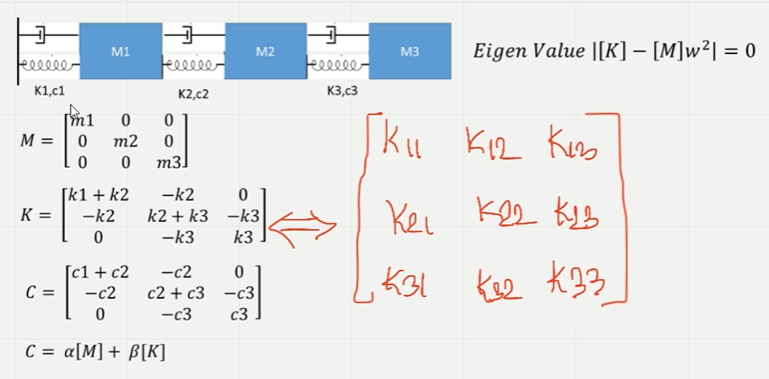


31
P4_Natural_Frequency_Calculation

In [ ]:
# Natural Frequencies of system

import numpy as np
from scipy import linalg

m1,m2,m3 = (1,1,1)
k1,k2,k3 = (1600,1600,1600)

M = np.array ([[m1,0,0],
               [0,m2,0],
               [0,0,m3]])

K = np.array ([[k1+k2,-k2,0],
               [-k2,k2+k3,-k3],
               [0,-k3,k3]])

u,v = linalg.eigh(K,M)

nat_freq = np.sqrt(u)

print("First natural frequency :",nat_freq[0])
print("Second natural frequency :",nat_freq[1])
print("Third natural frequency :",nat_freq[2])

My_code